# Grid versus Latin hypercube for the Hannover FEM surrogate

This notebook compares **equal-size FEM training designs** for the existing 2-input, 6-output MLP. It uses the results generated by `src/run_doe_experiment.py`; measured frequencies are used **only for final evaluation**. The original 1,176-row FEM dataset and the FEM implementation are unchanged.

To regenerate the experiment from the project root after installing `requirements-ml.txt` in a Python environment:

```bash
python src/run_doe_experiment.py
```

The command writes four small files under `data/generated/doe_comparison/`: design points, validation/test metrics, experimental metrics, and training-run metadata, plus a manifest. The benchmark takes several minutes on a typical laptop.

In [1]:
from pathlib import Path
from hashlib import sha256
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/generated/doe_comparison/manifest.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the project root after running src/run_doe_experiment.py')
DATA = ROOT / 'data/generated/doe_comparison'
manifest = json.loads((DATA / 'manifest.json').read_text())
source_csv = ROOT / 'data/generated/fem_dataset.csv'
assert sha256(source_csv.read_bytes()).hexdigest() == manifest['csv_sha256']
assert sha256((ROOT / 'src/mass_changes.py').read_bytes()).hexdigest() == manifest['model_sha256']
points = pd.read_csv(DATA / 'design_points.csv')
tests = pd.read_csv(DATA / 'test_metrics.csv')
experiments = pd.read_csv(DATA / 'experimental_metrics.csv')
runs = pd.read_csv(DATA / 'training_runs.csv')
assert set(tests.split) == {'val', 'test', 'test_edge'}
assert len(runs) == 13 and len(points) == 2400
print('Budgets:', manifest['budgets'], '| seeds:', manifest['seeds'])
print('Original 966-case baseline plus 12 matched-budget MLP runs.')
print('Experimental data role:', manifest['experimental_data_role'])

Budgets: [200, 400] | seeds: [11, 22, 33]
Original 966-case baseline plus 12 matched-budget MLP runs.
Experimental data role: evaluation only; 34 added-mass cases, paired shift estimates averaged per case


## Design and controls

Both designs use the same number of FEM calls: **200 or 400** training configurations. The grid uses 20 or 40 allowed positions crossed with 10 mass levels. The **anchored LHD** uses SciPy's two-dimensional Latin hypercube for the remaining $N-4$ points and adds the same four domain corners as the grid. Position is mapped to an allowed integer FEM node; LHD mass is continuous from 1 to 50 g. Quantization means the final node values are not a perfect continuous Latin hypercube. [SciPy's LHS documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.LatinHypercube.html) describes the underlying stratification.

For each budget, three seeds vary the MLP initialization and LHD draw. The **same architecture, optimizer, training-only scaling, validation positions (30, 50, 70, 90, 110 cm), interior test positions (40, 60, 80, 100 cm), and 120 cm edge test** are used throughout. The experimental configurations never determine training points or checkpoints. The original 966-case grid is retrained separately as a reference for this experiment.

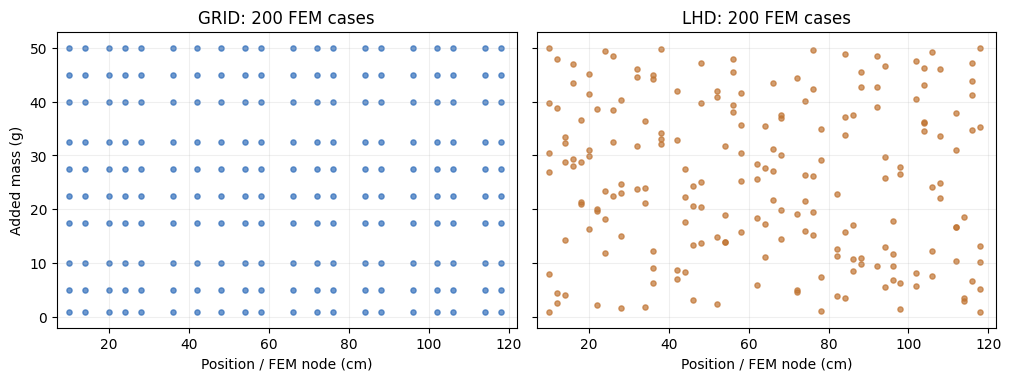

,design,budget,design_seed,cases,unique_positions
0,grid,200,0,200,20
1,grid,400,0,400,40
2,lhd,200,11,200,46
3,lhd,200,22,200,46
4,lhd,200,33,200,46
5,lhd,400,11,400,46
6,lhd,400,22,400,46
7,lhd,400,33,400,46


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained', sharex=True, sharey=True)
for ax, design, seed, color in zip(axes, ('grid', 'lhd'), (0, 11), ('#2f6dba', '#c07432')):
    sample = points[(points.design == design) & (points.budget == 200) &
                    (points.design_seed == seed)]
    assert len(sample) == 200
    ax.scatter(sample.position_cm, sample.mass_g, s=14, alpha=.7, color=color)
    ax.set(xlabel='Position / FEM node (cm)', title=f'{design.upper()}: 200 FEM cases',
           xlim=(7, 122), ylim=(-2, 53))
    ax.grid(alpha=.2)
axes[0].set_ylabel('Added mass (g)')
plt.show()
display(points.groupby(['design', 'budget', 'design_seed']).agg(
    cases=('mass_g', 'size'), unique_positions=('position_cm', 'nunique')).reset_index())

## MLP error against the FEM

The metric is the mean absolute error (**MAE, Hz**) over all six frequencies and all cases in a split. The table reports the mean and observed range over **three runs**, not a confidence interval. Test cases are identical for both designs; 120 cm is outside the training position range.

,design,budget,split,mean,min,max
0,grid,200,test,0.1394,0.0912,0.2045
1,grid,200,test_edge,0.6657,0.5449,0.8099
3,grid,400,test,0.0631,0.0463,0.0952
4,grid,400,test_edge,0.5996,0.4703,0.7665
6,lhd,200,test,0.0845,0.0759,0.0955
7,lhd,200,test_edge,0.7946,0.6830,0.9722
9,lhd,400,test,0.0590,0.0449,0.0831
10,lhd,400,test_edge,0.7108,0.5454,1.0206
12,original_grid,966,test,0.0185,0.0185,0.0185
13,original_grid,966,test_edge,0.3943,0.3943,0.3943


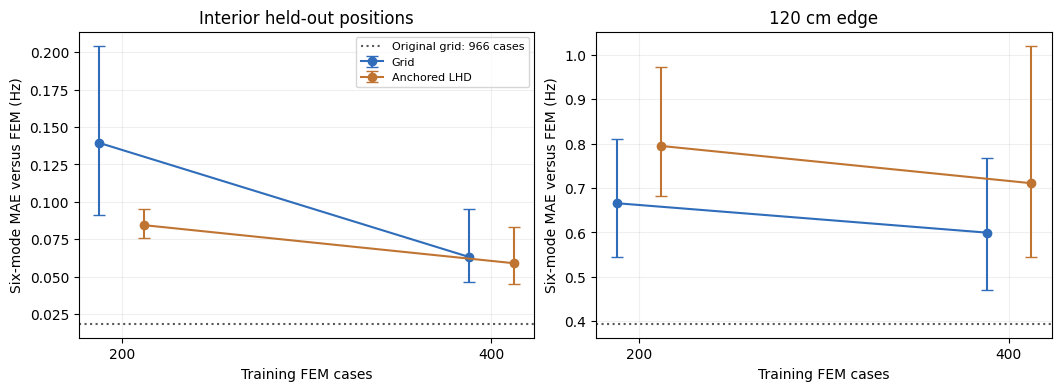

In [3]:
per_run = tests.groupby(['design', 'budget', 'seed', 'model', 'split'], as_index=False).mae_hz.mean()
mlp_run = per_run[per_run.model == 'MLP']
mlp_summary = mlp_run.groupby(['design', 'budget', 'split']).mae_hz.agg(['mean', 'min', 'max']).reset_index()
display(mlp_summary[mlp_summary.split.isin(['test', 'test_edge'])].round(4))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), layout='constrained')
for ax, split, title in zip(axes, ('test', 'test_edge'),
                             ('Interior held-out positions', '120 cm edge')):
    for design, label, color, offset in [('grid', 'Grid', '#2f6dba', -.06),
                                          ('lhd', 'Anchored LHD', '#c07432', .06)]:
        rows = mlp_summary[(mlp_summary.design == design) & (mlp_summary.split == split)]
        x = rows.budget.to_numpy() + offset * 200
        y = rows['mean'].to_numpy()
        ax.errorbar(x, y, yerr=[y - rows['min'].to_numpy(), rows['max'].to_numpy() - y],
                    fmt='o-', capsize=4, color=color, label=label)
    original = mlp_run[(mlp_run.design == 'original_grid') & (mlp_run.split == split)].mae_hz.iloc[0]
    ax.axhline(original, color='0.35', ls=':', label='Original grid: 966 cases')
    ax.set(xlabel='Training FEM cases', ylabel='Six-mode MAE versus FEM (Hz)',
           title=title, xticks=[200, 400])
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()

## Final check against measurements

The 34 measured added-mass configurations evaluate modes **2–4**. Each configuration has equal weight, after averaging its repeated paired frequency shifts. The metric here is **MAE of relative frequency shift in percentage points (pp)**. The FEM-to-experiment column is the physical-model discrepancy and is identical for every DOE. The three MAEs do **not** add; only the signed errors add case by case.

,design,budget,model,surrogate_fem_mae_pp,fem_experiment_mae_pp,surrogate_experiment_mae_pp
0,grid,200,MLP,0.2126,0.1885,0.3425
1,grid,400,MLP,0.1300,0.1885,0.2747
2,lhd,200,MLP,0.1536,0.1885,0.2732
3,lhd,400,MLP,0.1567,0.1885,0.2977
4,original_grid,966,MLP,0.0991,0.1885,0.2621


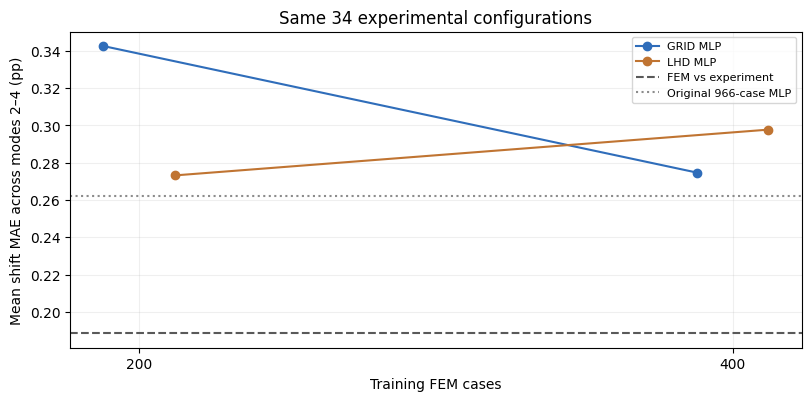

In [4]:
exp_summary = experiments.groupby(['design', 'budget', 'model'])[
    ['surrogate_fem_mae_pp', 'fem_experiment_mae_pp', 'surrogate_experiment_mae_pp']].mean().reset_index()
display(exp_summary.round(4))
fem_exp = exp_summary.fem_experiment_mae_pp.iloc[0]

plot_rows = exp_summary[(exp_summary.model == 'MLP') &
                        exp_summary.design.isin(['grid', 'lhd'])]
fig, ax = plt.subplots(figsize=(8, 3.9), layout='constrained')
for design, color, offset in [('grid', '#2f6dba', -.06), ('lhd', '#c07432', .06)]:
    rows = plot_rows[plot_rows.design == design].sort_values('budget')
    ax.plot(rows.budget + offset * 200, rows.surrogate_experiment_mae_pp,
            marker='o', color=color, label=f'{design.upper()} MLP')
ax.axhline(fem_exp, color='0.35', ls='--', label='FEM vs experiment')
original = exp_summary[(exp_summary.design == 'original_grid') &
                       (exp_summary.model == 'MLP')].surrogate_experiment_mae_pp.iloc[0]
ax.axhline(original, color='0.55', ls=':', label='Original 966-case MLP')
ax.set(xlabel='Training FEM cases', ylabel='Mean shift MAE across modes 2–4 (pp)',
       title='Same 34 experimental configurations', xticks=[200, 400])
ax.grid(alpha=.2)
ax.legend(fontsize=8)
plt.show()

## Conclusions and limits

- **MLP, 200 cases:** anchored LHD improves the interior test mean from **0.139 to 0.084 Hz** (three-run means). At 120 cm it is worse: **0.795 versus 0.666 Hz**.
- **MLP, 400 cases:** interior means are close (**0.059 LHD, 0.063 grid Hz**); their three-run ranges overlap. Grid remains better at 120 cm (**0.600 versus 0.711 Hz**).
- **More cases still help:** the separately retrained original 966-case grid reaches **0.0185 Hz** on the interior test and **0.394 Hz** at 120 cm. Its values differ slightly from the saved earlier MLP notebook because this is a separate training run.
- **Experiments do not disappear:** FEM-to-experiment shift MAE is **0.189 pp** averaged over modes 2–4. The MLP-to-experiment mean is **0.273 pp** for LHD versus **0.343 pp** for grid at 200 cases, but **0.298 versus 0.275 pp** at 400 cases. A DOE change alone does not correct the FEM's physical discrepancy.

Only three seeds were run, the interior test has four held-out positions, and the edge test has one. These are descriptive results, not a statistical proof that either DOE is generally superior. The LHD uses continuous masses and integer-position quantization, plus four boundary anchors; the grid uses 10 mass levels, so the designs differ in mass resolution as well as spatial placement. If 120 cm is an intended operating point, a next experiment should include training points there and reserve different masses at 120 cm for an independent test.